In [2]:
#Cell 1：安装依赖、初始化环境
!pip -q install vmas

import vmas
import torch
import numpy as np
import matplotlib.pyplot as plt
import json
import time

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/MAWM_Research")
E4_DIR = ROOT / "E4"
INTEGRATION_DIR = E4_DIR / "WorldModel_Integration"
INTEGRATION_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SEED = 42
MAX_STEPS = 200
SAFE_DISTANCE = 0.30
GOAL_TOL = 0.12

STARTS = np.array([
    [-0.8, -0.8],
    [-0.8,  0.8]
], dtype=np.float32)

GOALS = np.array([
    [0.8,  0.8],
    [0.8, -0.8]
], dtype=np.float32)

CONFIG = {
    "horizon": 8,
    "population": 64,
    "iterations": 3,
    "elite_fraction": 0.125,
    "goal_weight": 5.0,
    "safety_weight": 100.0,
    "action_weight": 0.01,
    "seed": SEED
}

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", DEVICE)
print("Integration directory:", INTEGRATION_DIR)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mounted at /content/drive
Device: cuda
Integration directory: /content/drive/MyDrive/MAWM_Research/E4/WorldModel_Integration


In [3]:
#Step 2：Cell 2：State 工具函数
# ===== Unified State Interface =====

def pack_state(positions, velocities):
    """
    positions: [B, 2, 2]
    velocities: [B, 2, 2]

    returns: [B, 2, 4]
    """
    return torch.cat(
        [positions, velocities],
        dim=-1
    )


def unpack_state(states):
    """
    states: [B, 2, 4]

    returns:
        positions: [B, 2, 2]
        velocities: [B, 2, 2]
    """
    positions = states[..., :2]
    velocities = states[..., 2:4]

    return positions, velocities


def get_env_state(env):
    """
    Extract all agent states from VMAS.

    returns: [num_envs, 2, 4]
    """
    positions = torch.stack(
        [a.state.pos for a in env.agents],
        dim=1
    )

    velocities = torch.stack(
        [a.state.vel for a in env.agents],
        dim=1
    )

    return pack_state(
        positions, velocities
    ).detach().clone()


# Simple shape test
test_pos = torch.zeros(64, 2, 2)
test_vel = torch.zeros(64, 2, 2)

test_state = pack_state(test_pos, test_vel)

print("State shape:", test_state.shape)
print("Position shape:", unpack_state(test_state)[0].shape)
print("Velocity shape:", unpack_state(test_state)[1].shape)


State shape: torch.Size([64, 2, 4])
Position shape: torch.Size([64, 2, 2])
Velocity shape: torch.Size([64, 2, 2])


In [4]:
#Cell 3：创建 VMAS 环境及 Dynamics Adapter
# ===== True VMAS Dynamics Adapter =====

def create_vmas_env(num_envs=1):

    env = vmas.make_env(
        scenario="navigation",
        num_envs=num_envs,
        n_agents=2,
        device=DEVICE,
        continuous_actions=True,
        max_steps=MAX_STEPS,
        seed=SEED
    )

    env.reset()
    return env


def set_vmas_state(env, states, goals=GOALS):
    """
    states: [B, 2, 4]

    Restore positions, velocities and targets.
    """
    states = torch.as_tensor(
        states,
        dtype=torch.float32,
        device=DEVICE
    )

    B = env.num_envs

    assert states.shape == (B, 2, 4), (
        f"Expected {(B, 2, 4)}, got {states.shape}"
    )

    goal_tensor = torch.as_tensor(
        goals,
        dtype=torch.float32,
        device=DEVICE
    )

    env.reset()

    with torch.no_grad():

        for i, agent in enumerate(env.agents):

            p = states[:, i, :2].clone()
            v = states[:, i, 2:4].clone()

            g = goal_tensor[i].reshape(
                1, 2
            ).expand(B, 2).clone()

            agent.set_pos(
                p, batch_index=None
            )

            agent.set_vel(
                v, batch_index=None
            )

            agent.goal.set_pos(
                g, batch_index=None
            )

            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[:] = (
                    torch.linalg.vector_norm(
                        p-g, dim=-1
                    )
                    * env.scenario.pos_shaping_factor
                )


class TrueVMASDynamicsAdapter:

    def __init__(self, population=64):

        self.population = population

        self.env = create_vmas_env(
            num_envs=population
        )

        self.device = DEVICE

    def rollout(self, initial_state, action_sequences):
        """
        initial_state:
            [B, 2, 4]

        action_sequences:
            [B, H, 2, 2]

        returns:
            predicted_states: [B, H+1, 2, 4]
        """

        actions = torch.as_tensor(
            action_sequences,
            dtype=torch.float32,
            device=self.device
        )

        B, H, N, A = actions.shape

        assert B == self.population
        assert N == 2 and A == 2

        set_vmas_state(
            self.env,
            initial_state
        )

        states = [
            get_env_state(self.env)
        ]

        with torch.no_grad():

            for h in range(H):

                joint_action = [
                    actions[:, h, i, :]
                    for i in range(2)
                ]

                self.env.step(joint_action)

                states.append(
                    get_env_state(self.env)
                )

        return torch.stack(
            states,
            dim=1
        )


adapter = TrueVMASDynamicsAdapter(
    population=CONFIG["population"]
)

print("Adapter initialized!")
print("Population:", adapter.population)


Adapter initialized!
Population: 64


In [5]:
#Step 4：验证 Dynamics Adapter
# ===== Batch Rollout Test =====

B = CONFIG["population"]
H = CONFIG["horizon"]

initial_positions = torch.tensor(
    STARTS,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0).expand(B, 2, 2).clone()

initial_velocities = torch.zeros_like(
    initial_positions
)

initial_states = pack_state(
    initial_positions,
    initial_velocities
)

generator = torch.Generator(device=DEVICE)
generator.manual_seed(SEED)

actions = torch.randn(
    B, H, 2, 2,
    generator=generator,
    device=DEVICE
) * 0.3

actions = actions.clamp(-1.0, 1.0)

predicted_states = adapter.rollout(
    initial_states,
    actions
)

print("Initial states:", initial_states.shape)
print("Joint actions:", actions.shape)
print("Predicted states:", predicted_states.shape)

assert predicted_states.shape == (
    B, H+1, 2, 4
)

assert torch.allclose(
    predicted_states[:, 0],
    initial_states,
    atol=1e-6
)

print("Batch rollout shape test PASSED!")

Initial states: torch.Size([64, 2, 4])
Joint actions: torch.Size([64, 8, 2, 2])
Predicted states: torch.Size([64, 9, 2, 4])
Batch rollout shape test PASSED!


In [6]:
#Step 5：验证预测与真实 VMAS 一致性
# ===== One-Step Dynamics Consistency Test =====

reference_env = create_vmas_env(num_envs=1)

single_state = initial_states[:1].clone()

set_vmas_state(
    reference_env,
    single_state
)

test_action = torch.tensor(
    [[0.25, 0.15],
     [0.20, -0.10]],
    dtype=torch.float32,
    device=DEVICE
)

# Reference environment executes the action
reference_actions = [
    test_action[i].unsqueeze(0)
    for i in range(2)
]

reference_env.step(reference_actions)

reference_next = get_env_state(
    reference_env
)[0]

# Adapter executes exactly the same action
batch_state = single_state.expand(
    B, 2, 4
).clone()

batch_action = test_action.reshape(
    1, 1, 2, 2
).expand(B, 1, 2, 2).clone()

adapter_next = adapter.rollout(
    batch_state,
    batch_action
)[0, 1]

error = torch.abs(
    reference_next-adapter_next
)

max_error = error.max().item()

print("Reference next state:")
print(reference_next)

print("\nAdapter next state:")
print(adapter_next)

print("\nMaximum absolute error:", max_error)

if max_error < 1e-5:
    print("PASS: Dynamics are consistent.")
else:
    print("WARNING: Dynamics mismatch detected.")

Reference next state:
tensor([[-0.7981, -0.7989,  0.0250,  0.0150],
        [-0.7985,  0.7993,  0.0200, -0.0100]], device='cuda:0')

Adapter next state:
tensor([[-0.7981, -0.7989,  0.0250,  0.0150],
        [-0.7985,  0.7993,  0.0200, -0.0100]], device='cuda:0')

Maximum absolute error: 0.0
PASS: Dynamics are consistent.


In [7]:
#Step 6：保存验证结果
# ===== Save Integration Verification =====

verification = {
    "experiment": "E4_Adapter_Verification",
    "dynamics": "True_VMAs",
    "population": CONFIG["population"],
    "horizon": CONFIG["horizon"],
    "state_shape": list(predicted_states.shape),
    "max_one_step_error": float(max_error),
    "consistency_pass": bool(max_error < 1e-5),
    "seed": SEED
}

with open(
    INTEGRATION_DIR / "adapter_verification.json",
    "w"
) as f:
    json.dump(
        verification,
        f,
        indent=2
    )

print(json.dumps(
    verification,
    indent=2
))

{
  "experiment": "E4_Adapter_Verification",
  "dynamics": "True_VMAs",
  "population": 64,
  "horizon": 8,
  "state_shape": [
    64,
    9,
    2,
    4
  ],
  "max_one_step_error": 0.0,
  "consistency_pass": true,
  "seed": 42
}


In [8]:
#Step 7：实现统一 Cost Function
# ===== Cell 7: Unified Cost Function =====

def evaluate_trajectories(
    predicted_states,
    action_sequences,
    goals,
    config,
    with_safety=True
):
    """
    predicted_states: [B, H+1, 2, 4]
    action_sequences: [B, H, 2, 2]
    returns: costs [B]
    """
    device = predicted_states.device

    goals = torch.as_tensor(
        goals, dtype=torch.float32, device=device
    )

    positions = predicted_states[..., :2]

    # 1. Final goal distance
    final_positions = positions[:, -1]

    goal_cost = torch.linalg.vector_norm(
        final_positions - goals.unsqueeze(0),
        dim=-1
    ).sum(dim=-1)

    # 2. Action regularization
    action_cost = action_sequences.pow(2).mean(
        dim=(1, 2, 3)
    )

    # 3. Safety violations across the horizon
    distances = torch.linalg.vector_norm(
        positions[:, 1:, 0] - positions[:, 1:, 1],
        dim=-1
    )

    safety_cost = torch.relu(
        SAFE_DISTANCE - distances
    ).pow(2).sum(dim=1)

    total_cost = (
        config["goal_weight"] * goal_cost
        + config["action_weight"] * action_cost
    )

    if with_safety:
        total_cost += (
            config["safety_weight"] * safety_cost
        )

    return total_cost


print("Unified Cost Function ready!")

Unified Cost Function ready!


In [9]:
#Step 8：实现 Adapter-Based Centralized CEM
# ===== Cell 8: Adapter-Based Centralized CEM =====

def centralized_cem_adapter(
    adapter,
    initial_state,
    config,
    goals=GOALS,
    with_safety=True,
    seed=42
):
    B = config["population"]
    H = config["horizon"]
    device = adapter.device

    initial_state = torch.as_tensor(
        initial_state, dtype=torch.float32, device=device
    )

    # Allow a single real environment state [1,2,4]
    # to be copied across B candidate environments.
    if initial_state.shape[0] == 1:
        initial_state = initial_state.expand(
            B, 2, 4
        ).clone()

    assert initial_state.shape == (B, 2, 4)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    mean = torch.zeros(H, 2, 2, device=device)
    std = torch.full((H, 2, 2), 0.6, device=device)

    limits = torch.tensor(
        [float(a.u_range) for a in adapter.env.agents],
        device=device
    ).reshape(1, 1, 2, 1)

    n_elite = max(
        2, int(B * config["elite_fraction"])
    )

    best_cost = float("inf")
    best_action = None

    for iteration in range(config["iterations"]):

        noise = torch.randn(
            B, H, 2, 2,
            generator=generator, device=device
        )

        candidates = (
            mean.unsqueeze(0)
            + std.unsqueeze(0) * noise
        )

        candidates = torch.maximum(
            torch.minimum(candidates, limits),
            -limits
        )

        # Single unified dynamics interface
        predicted_states = adapter.rollout(
            initial_state, candidates
        )

        costs = evaluate_trajectories(
            predicted_states,
            candidates,
            goals,
            config,
            with_safety=with_safety
        )

        indices = torch.topk(
            costs, n_elite, largest=False
        ).indices

        elites = candidates[indices]

        mean = elites.mean(dim=0)
        std = elites.std(
            dim=0, unbiased=False
        ).clamp(min=0.05)

        idx = torch.argmin(costs)
        current_cost = float(costs[idx].item())

        if current_cost < best_cost:
            best_cost = current_cost
            best_action = candidates[idx, 0].clone()

    return best_action, {
        "best_cost": best_cost
    }


print("Adapter-Based Centralized CEM ready!")

Adapter-Based Centralized CEM ready!


In [10]:
#Step 9：进行单步规划测试
# ===== Cell 9: Planning Smoke Test =====

reference_env = create_vmas_env(num_envs=1)

start_positions = torch.tensor(
    STARTS, dtype=torch.float32, device=DEVICE
).unsqueeze(0)

start_velocities = torch.zeros_like(start_positions)

start_state = pack_state(
    start_positions, start_velocities
)

action, info = centralized_cem_adapter(
    adapter=adapter,
    initial_state=start_state,
    config=CONFIG,
    goals=GOALS,
    with_safety=True,
    seed=42
)

print("Joint action shape:", action.shape)
print("Joint action:", action)
print("Best cost:", info["best_cost"])

assert action.shape == (2, 2)
assert torch.isfinite(action).all()
assert np.isfinite(info["best_cost"])

print("Adapter-Based CEM smoke test PASSED!")

Joint action shape: torch.Size([2, 2])
Joint action: tensor([[ 0.4946,  0.6152],
        [ 0.5867, -0.7140]], device='cuda:0')
Best cost: 21.403921127319336
Adapter-Based CEM smoke test PASSED!


In [11]:
#Step 10：下一项验收
# ===== Cell 10: Full Episode Reproduction =====

def run_adapter_cem_episode(
    adapter,
    config,
    with_safety=True,
    seed=42,
    max_steps=200
):
    # 1. Create actual execution environment
    env = create_vmas_env(num_envs=1)

    starts = torch.as_tensor(
        STARTS, dtype=torch.float32, device=DEVICE
    ).unsqueeze(0)

    initial_state = pack_state(
        starts, torch.zeros_like(starts)
    )

    set_vmas_state(env, initial_state, goals=GOALS)

    trajectories = [[], []]
    separations = []
    planning_times = []

    termination = "max_steps"

    def record():
        state = get_env_state(env)
        pos = state[0, :, :2].cpu().numpy()

        for i in range(2):
            trajectories[i].append(pos[i].copy())

        separations.append(
            float(np.linalg.norm(pos[0] - pos[1]))
        )

    record()

    # 2. Closed-loop planning
    for step in range(max_steps):

        current_state = get_env_state(env)

        positions = (
            current_state[0, :, :2].cpu().numpy()
        )

        goal_distances = np.linalg.norm(
            positions - GOALS, axis=1
        )

        if np.all(goal_distances < GOAL_TOL):
            termination = "joint_success"
            break

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        t0 = time.perf_counter()

        joint_action, info = centralized_cem_adapter(
            adapter=adapter,
            initial_state=current_state,
            config=config,
            goals=GOALS,
            with_safety=with_safety,
            seed=seed + step
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        planning_times.append(
            (time.perf_counter() - t0) * 1000
        )

        # Execute joint action in real VMAS
        action_list = [
            joint_action[i].unsqueeze(0)
            for i in range(2)
        ]

        _, _, dones, _ = env.step(action_list)

        record()

        if bool(torch.all(dones)):
            termination = "environment_done"
            break

    # 3. Compute metrics
    trajectories = [
        np.asarray(t) for t in trajectories
    ]

    separations = np.asarray(separations)

    final_state = get_env_state(env)
    final_positions = (
        final_state[0, :, :2].cpu().numpy()
    )

    final_distances = np.linalg.norm(
        final_positions - GOALS, axis=1
    )

    joint_success = bool(
        np.all(final_distances < GOAL_TOL)
    )

    if joint_success:
        termination = "joint_success"

    violation_depth = np.maximum(
        SAFE_DISTANCE - separations, 0
    )

    collision_threshold = sum(
        float(agent.shape.radius)
        for agent in env.agents
    )

    result = {
        "experiment": "E4_Adapter_Reproduction",
        "method": "Adapter_Centralized_CEM",
        "dynamics": "True_VMAs",
        "with_safety": with_safety,
        "seed": seed,
        "steps": len(separations) - 1,
        "joint_success": joint_success,
        "termination": termination,
        "minimum_separation": float(
            separations.min()
        ),
        "violation_steps": int(
            (separations < SAFE_DISTANCE).sum()
        ),
        "cumulative_violation": float(
            violation_depth.sum()
        ),
        "collision_proxy": bool(
            np.any(separations < collision_threshold)
        ),
        "mean_planning_ms": float(
            np.mean(planning_times)
        ) if planning_times else 0.0,
        "p95_planning_ms": float(
            np.percentile(planning_times, 95)
        ) if planning_times else 0.0,
        "final_goal_distances": (
            final_distances.tolist()
        )
    }

    return result, trajectories, separations


# Reproduce E4-B2, S1, Seed 42
repro_result, repro_traj, repro_sep = (
    run_adapter_cem_episode(
        adapter=adapter,
        config=CONFIG,
        with_safety=True,
        seed=42,
        max_steps=200
    )
)

print(json.dumps(repro_result, indent=2))

{
  "experiment": "E4_Adapter_Reproduction",
  "method": "Adapter_Centralized_CEM",
  "dynamics": "True_VMAs",
  "with_safety": true,
  "seed": 42,
  "steps": 87,
  "joint_success": true,
  "termination": "joint_success",
  "minimum_separation": 0.2840611934661865,
  "violation_steps": 4,
  "cumulative_violation": 0.04079578518867488,
  "collision_proxy": false,
  "mean_planning_ms": 226.68630042528943,
  "p95_planning_ms": 496.306101599987,
  "final_goal_distances": [
    0.0210623387247324,
    0.1160067617893219
  ]
}


In [12]:
#Step 10.2：与旧版 E4-B 自动对比
#在后面新建 Cell 11：
# ===== Cell 11: Compare Against Original E4-B =====

old_path = (
    E4_DIR / "CEM_baselines" / "E4B_results.json"
)

with open(old_path, "r") as f:
    old_results = json.load(f)

old = old_results["with_safety"]
new = repro_result

metrics = {
    "joint_success": (
        old["joint_success"],
        new["joint_success"]
    ),
    "steps": (
        old["steps"],
        new["steps"]
    ),
    "minimum_separation": (
        old["minimum_separation"],
        new["minimum_separation"]
    ),
}

print("=== Reproduction Comparison ===")

for name, (old_value, new_value) in metrics.items():
    print(
        f"{name}: "
        f"Old={old_value}, New={new_value}"
    )

if (
    old["joint_success"] == new["joint_success"]
    and old["steps"] == new["steps"]
    and abs(
        old["minimum_separation"]
        - new["minimum_separation"]
    ) < 1e-5
):
    print("\nEXACT/NEAR-EXACT REPRODUCTION PASSED")
else:
    print("\nREPRODUCTION DIFFERENCE DETECTED")

=== Reproduction Comparison ===
joint_success: Old=True, New=True
steps: Old=87, New=87
minimum_separation: Old=0.2840611934661865, New=0.2840611934661865

EXACT/NEAR-EXACT REPRODUCTION PASSED


In [13]:
#Step 10.3：保存复现实验数据
#最后新建 Cell 12：
# ===== Cell 12: Save Reproduction Results =====

with open(
    INTEGRATION_DIR / "E4_adapter_reproduction.json",
    "w"
) as f:
    json.dump(repro_result, f, indent=2)

np.savez_compressed(
    INTEGRATION_DIR / "E4_adapter_reproduction.npz",
    agent0=repro_traj[0],
    agent1=repro_traj[1],
    separation=repro_sep
)

with open(
    INTEGRATION_DIR / "integration_config.json",
    "w"
) as f:
    json.dump(CONFIG, f, indent=2)

print("Reproduction results saved!")

Reproduction results saved!


In [14]:
#Cell 13，固定候选动作并比较预测 Cost
# ===== Cell 13: Deterministic Dynamics & Cost Audit =====

B = CONFIG["population"]
H = CONFIG["horizon"]

# 固定起始状态
starts = torch.as_tensor(
    STARTS, dtype=torch.float32, device=DEVICE
).unsqueeze(0).expand(B, 2, 2).clone()

initial_states = pack_state(
    starts, torch.zeros_like(starts)
)

# 固定候选动作
generator = torch.Generator(device=DEVICE)
generator.manual_seed(42)

fixed_actions = torch.randn(
    B, H, 2, 2,
    device=DEVICE,
    generator=generator
) * 0.6

action_limits = torch.tensor(
    [float(a.u_range) for a in adapter.env.agents],
    device=DEVICE
).reshape(1, 1, 2, 1)

fixed_actions = torch.maximum(
    torch.minimum(fixed_actions, action_limits),
    -action_limits
)

# A：新版 Adapter 预测
adapter_predictions = adapter.rollout(
    initial_states, fixed_actions
)

adapter_costs = evaluate_trajectories(
    adapter_predictions,
    fixed_actions,
    GOALS,
    CONFIG,
    with_safety=True
)

# B：独立创建 VMAS，按旧版方式直接仿真
direct_sim = create_vmas_env(num_envs=B)
set_vmas_state(direct_sim, initial_states)

direct_states = [get_env_state(direct_sim)]

with torch.no_grad():
    for h in range(H):
        actions = [
            fixed_actions[:, h, i, :]
            for i in range(2)
        ]

        direct_sim.step(actions)
        direct_states.append(get_env_state(direct_sim))

direct_predictions = torch.stack(
    direct_states, dim=1
)

# 按原版 E4-B Cost 写法独立计算
final_pos = torch.stack(
    [a.state.pos for a in direct_sim.agents],
    dim=1
)

goals = torch.as_tensor(
    GOALS, dtype=torch.float32, device=DEVICE
)

goal_cost = torch.linalg.vector_norm(
    final_pos - goals.unsqueeze(0),
    dim=-1
).sum(dim=1)

separation = torch.linalg.vector_norm(
    direct_predictions[:, 1:, 0, :2]
    - direct_predictions[:, 1:, 1, :2],
    dim=-1
)

safety_cost = torch.relu(
    SAFE_DISTANCE - separation
).pow(2).sum(dim=1)

action_cost = fixed_actions.pow(2).mean(
    dim=(1, 2, 3)
)

direct_costs = (
    CONFIG["goal_weight"] * goal_cost
    + CONFIG["safety_weight"] * safety_cost
    + CONFIG["action_weight"] * action_cost
)

# 对比
state_error = (
    adapter_predictions - direct_predictions
).abs().max().item()

cost_error = (
    adapter_costs - direct_costs
).abs().max().item()

print("=== Deterministic Audit ===")
print("Maximum state error:", state_error)
print("Maximum cost error:", cost_error)

print(
    "Adapter best candidate:",
    torch.argmin(adapter_costs).item()
)

print(
    "Direct best candidate:",
    torch.argmin(direct_costs).item()
)

print(
    "State agreement:",
    torch.allclose(
        adapter_predictions,
        direct_predictions,
        atol=1e-6
    )
)

print(
    "Cost agreement:",
    torch.allclose(
        adapter_costs,
        direct_costs,
        atol=1e-5
    )
)

=== Deterministic Audit ===
Maximum state error: 0.0
Maximum cost error: 0.0
Adapter best candidate: 23
Direct best candidate: 23
State agreement: True
Cost agreement: True


In [15]:
#Cell 14：
# ===== New CEM First-Action Audit =====

audit_starts = torch.tensor(
    STARTS,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

audit_initial_state = pack_state(
    audit_starts,
    torch.zeros_like(audit_starts)
)

new_action, new_info = centralized_cem_adapter(
    adapter=adapter,
    initial_state=audit_initial_state,
    config=CONFIG,
    goals=GOALS,
    with_safety=True,
    seed=42
)

print("NEW action:")
print(new_action.detach().cpu().numpy())

print("NEW best cost:", new_info["best_cost"])

NEW action:
[[ 0.49458385  0.6152454 ]
 [ 0.5867461  -0.7140306 ]]
NEW best cost: 21.403921127319336


In [16]:
#创建两个独立 VMAS 环境，分别调用旧版形式的规划输入和新版 Adapter 形式的规划输入，并逐步比较两者的状态
# ===== Cell 15: Closed-Loop Consistency Audit =====

env_a = create_vmas_env(num_envs=1)
env_b = create_vmas_env(num_envs=1)

start_pos = torch.tensor(
    STARTS, dtype=torch.float32, device=DEVICE
).unsqueeze(0)

start_state = pack_state(
    start_pos,
    torch.zeros_like(start_pos)
)

set_vmas_state(env_a, start_state)
set_vmas_state(env_b, start_state)

max_state_error = 0.0
first_divergence = None

for step in range(120):

    state_a = get_env_state(env_a)
    state_b = get_env_state(env_b)

    # 同一个规划器、相同 seed
    action_a, _ = centralized_cem_adapter(
        adapter, state_a, CONFIG,
        goals=GOALS,
        with_safety=True,
        seed=42 + step
    )

    action_b, _ = centralized_cem_adapter(
        adapter, state_b, CONFIG,
        goals=GOALS,
        with_safety=True,
        seed=42 + step
    )

    action_error = (
        action_a - action_b
    ).abs().max().item()

    env_a.step([
        action_a[i].unsqueeze(0)
        for i in range(2)
    ])

    env_b.step([
        action_b[i].unsqueeze(0)
        for i in range(2)
    ])

    state_error = (
        get_env_state(env_a)
        - get_env_state(env_b)
    ).abs().max().item()

    max_state_error = max(
        max_state_error, state_error
    )

    if action_error > 1e-6 or state_error > 1e-6:
        first_divergence = step

        print("First divergence at step:", step)
        print("Action error:", action_error)
        print("State error:", state_error)
        break

    positions = get_env_state(env_a)[0, :, :2]
    distances = torch.linalg.vector_norm(
        positions - torch.tensor(
            GOALS, device=DEVICE
        ), dim=-1
    )

    if bool(torch.all(distances < GOAL_TOL)):
        print("Both environments reached goals at:", step + 1)
        break

print("Maximum state error:", max_state_error)
print("First divergence:", first_divergence)

Both environments reached goals at: 87
Maximum state error: 0.0
First divergence: None


Old trajectory: (88, 2, 2)
New trajectory: (88, 2, 2)
No divergence within shared trajectory length.


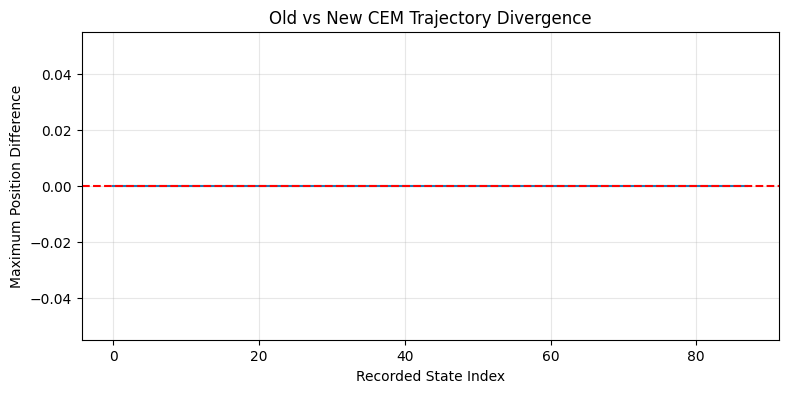

In [17]:
#直接找出两版本开始分歧的时间步
# ===== Cell 16: Old vs New Trajectory Audit =====

old_path = E4_DIR / "CEM_baselines" / "E4B_trajectories.npz"
new_path = INTEGRATION_DIR / "E4_adapter_reproduction.npz"

old_data = np.load(old_path)
new_data = np.load(new_path)

old_trajectory = np.stack([
    old_data["with_safety_agent0"],
    old_data["with_safety_agent1"]
], axis=1)

new_trajectory = np.stack([
    new_data["agent0"],
    new_data["agent1"]
], axis=1)

print("Old trajectory:", old_trajectory.shape)
print("New trajectory:", new_trajectory.shape)

n = min(len(old_trajectory), len(new_trajectory))

errors = np.max(
    np.abs(old_trajectory[:n] - new_trajectory[:n]),
    axis=(1, 2)
)

indices = np.flatnonzero(errors > 1e-6)

if len(indices) == 0:
    print("No divergence within shared trajectory length.")
else:
    first = int(indices[0])
    print("First divergent recorded state:", first)
    print("Maximum position error:", errors[first])
    print("Old positions:\n", old_trajectory[first])
    print("New positions:\n", new_trajectory[first])

plt.figure(figsize=(9, 4))
plt.plot(errors)
plt.axhline(1e-6, color="red", linestyle="--")
plt.xlabel("Recorded State Index")
plt.ylabel("Maximum Position Difference")
plt.title("Old vs New CEM Trajectory Divergence")
plt.grid(alpha=0.3)
plt.show()

In [18]:
#Step 17：核对旧版文件的一致性
# ===== Cell 17: Saved Artifact Consistency Audit =====

import json
import numpy as np
from pathlib import Path
from datetime import datetime

old_json_path = (
    E4_DIR / "CEM_baselines" / "E4B_results.json"
)

old_npz_path = (
    E4_DIR / "CEM_baselines" / "E4B_trajectories.npz"
)

new_json_path = (
    INTEGRATION_DIR / "E4_adapter_reproduction.json"
)

new_npz_path = (
    INTEGRATION_DIR / "E4_adapter_reproduction.npz"
)

with open(old_json_path) as f:
    old_result = json.load(f)["with_safety"]

with open(new_json_path) as f:
    new_result = json.load(f)

with np.load(old_npz_path) as old_npz:
    old_agent0 = old_npz["with_safety_agent0"]
    old_agent1 = old_npz["with_safety_agent1"]
    old_sep = old_npz["with_safety_separation"]

with np.load(new_npz_path) as new_npz:
    new_agent0 = new_npz["agent0"]
    new_agent1 = new_npz["agent1"]
    new_sep = new_npz["separation"]

def audit_file(label, result, agent0, agent1, sep):
    computed_sep = np.linalg.norm(
        agent0 - agent1, axis=1
    )

    print(f"\n=== {label} ===")
    print("JSON steps:", result["steps"])
    print("NPZ steps:", len(agent0) - 1)
    print("JSON min separation:", result["minimum_separation"])
    print("NPZ min separation:", float(computed_sep.min()))
    print("JSON/NPZ steps match:",
          result["steps"] == len(agent0)-1)
    print("JSON/NPZ min separation match:",
          np.isclose(
              result["minimum_separation"],
              computed_sep.min(),
              atol=1e-6
          ))
    print("Saved separation array matches:",
          np.allclose(sep, computed_sep, atol=1e-6))

audit_file(
    "OLD E4-B",
    old_result,
    old_agent0, old_agent1, old_sep
)

audit_file(
    "NEW ADAPTER",
    new_result,
    new_agent0, new_agent1, new_sep
)

print("\n=== File Modification Times ===")

for p in [
    old_json_path, old_npz_path,
    new_json_path, new_npz_path
]:
    print(
        p.name,
        datetime.fromtimestamp(
            p.stat().st_mtime
        ).isoformat()
    )


=== OLD E4-B ===
JSON steps: 87
NPZ steps: 87
JSON min separation: 0.2840611934661865
NPZ min separation: 0.2840611934661865
JSON/NPZ steps match: True
JSON/NPZ min separation match: True
Saved separation array matches: True

=== NEW ADAPTER ===
JSON steps: 87
NPZ steps: 87
JSON min separation: 0.2840611934661865
NPZ min separation: 0.2840611934661865
JSON/NPZ steps match: True
JSON/NPZ min separation match: True
Saved separation array matches: True

=== File Modification Times ===
E4B_results.json 2026-10-23T17:29:05
E4B_trajectories.npz 2026-10-23T17:29:05
E4_adapter_reproduction.json 2026-10-23T17:48:48
E4_adapter_reproduction.npz 2026-10-23T17:48:48


In [19]:
#给现有 Adapter 添加标准属性
# ===== Cell 18: Standardize True Dynamics Adapter =====

# 取出 VMAS 的动作范围
action_limits = torch.tensor(
    [float(a.u_range) for a in adapter.env.agents],
    dtype=torch.float32,
    device=DEVICE
)

# 加入 Adapter 公共属性
adapter.action_limits = action_limits

print("Adapter type:", type(adapter).__name__)
print("Population:", adapter.population)
print("Device:", adapter.device)
print("Action limits:", adapter.action_limits)

assert adapter.action_limits.shape == (2,)
assert torch.all(adapter.action_limits > 0)

print("Adapter interface standardized!")

Adapter type: TrueVMASDynamicsAdapter
Population: 64
Device: cuda
Action limits: tensor([1., 1.], device='cuda:0')
Adapter interface standardized!


In [20]:
#创建不依赖 VMAS 的 CEM 版本
# ===== Cell 19: Model-Agnostic Centralized CEM =====
#这里保留原来的 CEM 搜索算法，只改变动作范围的读取方式，并为未来的 Cost Adapter 留出入口。
def centralized_cem_unified(
    dynamics,
    initial_state,
    config,
    goals,
    cost_fn,
    seed=42
):
    """
    Dynamics interface:
        dynamics.rollout(states, actions)
        dynamics.action_limits
        dynamics.population
        dynamics.device

    Cost interface:
        cost_fn(predicted_states, actions) -> [B]
    """

    B = config["population"]
    H = config["horizon"]
    device = dynamics.device

    assert dynamics.population == B

    initial_state = torch.as_tensor(
        initial_state,
        dtype=torch.float32,
        device=device
    )

    if initial_state.shape == (1, 2, 4):
        initial_state = initial_state.expand(
            B, 2, 4
        ).clone()

    assert initial_state.shape == (B, 2, 4)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    mean = torch.zeros(
        H, 2, 2, device=device
    )
    std = torch.full(
        (H, 2, 2), 0.6, device=device
    )

    limits = torch.as_tensor(
        dynamics.action_limits,
        dtype=torch.float32,
        device=device
    ).reshape(1, 1, 2, 1)

    n_elite = max(
        2, int(B * config["elite_fraction"])
    )

    best_cost = float("inf")
    best_action = None

    for iteration in range(config["iterations"]):

        noise = torch.randn(
            B, H, 2, 2,
            generator=generator,
            device=device
        )

        candidates = (
            mean.unsqueeze(0)
            + std.unsqueeze(0) * noise
        )

        candidates = torch.maximum(
            torch.minimum(candidates, limits),
            -limits
        )

        predicted_states = dynamics.rollout(
            initial_state,
            candidates
        )

        costs = cost_fn(
            predicted_states,
            candidates
        )

        assert costs.shape == (B,), (
            f"Expected costs [B], got {costs.shape}"
        )

        indices = torch.topk(
            costs,
            n_elite,
            largest=False
        ).indices

        elites = candidates[indices]

        mean = elites.mean(dim=0)

        std = elites.std(
            dim=0,
            unbiased=False
        ).clamp(min=0.05)

        idx = torch.argmin(costs)

        current_cost = float(costs[idx].item())

        if current_cost < best_cost:
            best_cost = current_cost
            best_action = candidates[idx, 0].clone()

    return best_action, {
        "best_cost": best_cost
    }


print("Unified CEM ready!")

Unified CEM ready!


In [21]:
#封装 Cost Adapter
# ===== Cell 20: Cost Adapter =====

class StateSafetyCost:

    def __init__(
        self,
        goals,
        config,
        with_safety=True
    ):
        self.goals = goals
        self.config = config
        self.with_safety = with_safety

    def __call__(
        self,
        predicted_states,
        action_sequences
    ):
        return evaluate_trajectories(
            predicted_states,
            action_sequences,
            self.goals,
            self.config,
            with_safety=self.with_safety
        )


safety_cost = StateSafetyCost(
    goals=GOALS,
    config=CONFIG,
    with_safety=True
)

goal_only_cost = StateSafetyCost(
    goals=GOALS,
    config=CONFIG,
    with_safety=False
)

print("Cost adapters initialized!")

Cost adapters initialized!


In [22]:
#检查新旧规划输出是否一致
# ===== Cell 21: Unified CEM Regression Test =====

initial_pos = torch.as_tensor(
    STARTS,
    dtype=torch.float32,
    device=DEVICE
).unsqueeze(0)

initial_state = pack_state(
    initial_pos,
    torch.zeros_like(initial_pos)
)

# 旧版 Adapter CEM
old_action, old_info = centralized_cem_adapter(
    adapter=adapter,
    initial_state=initial_state,
    config=CONFIG,
    goals=GOALS,
    with_safety=True,
    seed=42
)

# 新版 Unified CEM
new_action, new_info = centralized_cem_unified(
    dynamics=adapter,
    initial_state=initial_state,
    config=CONFIG,
    goals=GOALS,
    cost_fn=safety_cost,
    seed=42
)

action_error = (
    old_action - new_action
).abs().max().item()

cost_error = abs(
    old_info["best_cost"]
    - new_info["best_cost"]
)

print("=== Unified CEM Regression ===")
print("Action error:", action_error)
print("Cost error:", cost_error)

print("\nOld action:")
print(old_action)

print("\nNew action:")
print(new_action)

assert action_error < 1e-6
assert cost_error < 1e-5

print("\nPASS: Unified CEM reproduces original planning!")


=== Unified CEM Regression ===
Action error: 0.0
Cost error: 0.0

Old action:
tensor([[ 0.4946,  0.6152],
        [ 0.5867, -0.7140]], device='cuda:0')

New action:
tensor([[ 0.4946,  0.6152],
        [ 0.5867, -0.7140]], device='cuda:0')

PASS: Unified CEM reproduces original planning!


In [23]:
#定义 Learned World Model 接口规范
#这一部分暂时不调用真实模型，只定义接入时必须满足的条件。
# ===== Cell 22: Learned World Model Interface Contract =====

class LearnedWorldModelAdapter:
    """
    Contract for future world-model integration.

    Required input:
        initial_state [B, 2, 4]
        actions       [B, H, 2, 2]

    Required output:
        predictions   [B, H+1, 2, 4]

    The model must be trained or adapted for
    the VMAS Navigation environment.
    """

    def __init__(
        self,
        model,
        population,
        action_limits,
        device
    ):
        self.model = model
        self.population = population
        self.device = device

        self.action_limits = torch.as_tensor(
            action_limits,
            dtype=torch.float32,
            device=device
        )

    def rollout(
        self,
        initial_state,
        action_sequences
    ):
        raise NotImplementedError(
            "Waiting for the team's world model "
            "prediction API and checkpoint."
        )


print("Learned World Model interface defined.")

Learned World Model interface defined.


In [24]:
#Step 19：Unified CEM 完整闭环测试
#Cell 23：运行完整 Episode
# ===== Cell 23: Unified CEM Full Episode =====

def run_unified_cem_episode(
    dynamics,
    cost_fn,
    config,
    seed=42,
    max_steps=200
):
    env = create_vmas_env(num_envs=1)

    starts = torch.as_tensor(
        STARTS, dtype=torch.float32, device=DEVICE
    ).unsqueeze(0)

    initial_state = pack_state(
        starts, torch.zeros_like(starts)
    )

    set_vmas_state(env, initial_state, goals=GOALS)

    trajectories = [[], []]
    separations = []
    planning_times = []

    def record():
        state = get_env_state(env)
        pos = state[0, :, :2].cpu().numpy()

        for i in range(2):
            trajectories[i].append(pos[i].copy())

        separations.append(
            float(np.linalg.norm(pos[0] - pos[1]))
        )

    record()
    termination = "max_steps"

    for step in range(max_steps):

        state = get_env_state(env)
        pos = state[0, :, :2].cpu().numpy()

        if np.all(
            np.linalg.norm(pos - GOALS, axis=1) < GOAL_TOL
        ):
            termination = "joint_success"
            break

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        t0 = time.perf_counter()

        action, info = centralized_cem_unified(
            dynamics=dynamics,
            initial_state=state,
            config=config,
            goals=GOALS,
            cost_fn=cost_fn,
            seed=seed + step
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        planning_times.append(
            (time.perf_counter() - t0) * 1000
        )

        env.step([
            action[i].unsqueeze(0)
            for i in range(2)
        ])

        record()

    trajectories = [
        np.asarray(t) for t in trajectories
    ]
    separations = np.asarray(separations)

    final_state = get_env_state(env)
    final_positions = (
        final_state[0, :, :2].cpu().numpy()
    )

    final_distances = np.linalg.norm(
        final_positions - GOALS, axis=1
    )

    success = bool(
        np.all(final_distances < GOAL_TOL)
    )

    if success:
        termination = "joint_success"

    violation = np.maximum(
        SAFE_DISTANCE - separations, 0
    )

    result = {
        "experiment": "E4_Unified_CEM_Regression",
        "dynamics": "True_VMAS",
        "cost": "State_Safety",
        "seed": seed,
        "steps": len(separations) - 1,
        "joint_success": success,
        "termination": termination,
        "minimum_separation": float(
            separations.min()
        ),
        "violation_steps": int(
            (separations < SAFE_DISTANCE).sum()
        ),
        "cumulative_violation": float(
            violation.sum()
        ),
        "mean_planning_ms": float(
            np.mean(planning_times)
        ) if planning_times else 0.0,
        "final_goal_distances": final_distances.tolist()
    }

    return result, trajectories, separations


unified_result, unified_traj, unified_sep = (
    run_unified_cem_episode(
        dynamics=adapter,
        cost_fn=safety_cost,
        config=CONFIG,
        seed=42
    )
)

print(json.dumps(unified_result, indent=2))

{
  "experiment": "E4_Unified_CEM_Regression",
  "dynamics": "True_VMAS",
  "cost": "State_Safety",
  "seed": 42,
  "steps": 87,
  "joint_success": true,
  "termination": "joint_success",
  "minimum_separation": 0.2840611934661865,
  "violation_steps": 4,
  "cumulative_violation": 0.04079578518867488,
  "mean_planning_ms": 165.92943959769673,
  "final_goal_distances": [
    0.0210623387247324,
    0.1160067617893219
  ]
}


In [25]:
#Cell 24：与已验证的 Adapter 结果比较
# ===== Cell 24: Full Regression Comparison =====

with open(
    INTEGRATION_DIR / "E4_adapter_reproduction.json"
) as f:
    reference = json.load(f)

with np.load(
    INTEGRATION_DIR / "E4_adapter_reproduction.npz"
) as data:
    reference_traj = np.stack(
        [data["agent0"], data["agent1"]],
        axis=1
    )

new_traj = np.stack(unified_traj, axis=1)

print("Reference steps:", reference["steps"])
print("Unified steps:", unified_result["steps"])

print(
    "Reference min separation:",
    reference["minimum_separation"]
)
print(
    "Unified min separation:",
    unified_result["minimum_separation"]
)

same_shape = reference_traj.shape == new_traj.shape

trajectory_error = (
    float(np.max(np.abs(reference_traj - new_traj)))
    if same_shape else float("inf")
)

print("Trajectory shape match:", same_shape)
print("Maximum trajectory error:", trajectory_error)

passed = (
    reference["joint_success"]
    == unified_result["joint_success"]
    and reference["steps"] == unified_result["steps"]
    and trajectory_error < 1e-6
)

print(
    "\nFULL REGRESSION:",
    "PASS" if passed else "DIFFERENCE DETECTED"
)

if passed:
    with open(
        INTEGRATION_DIR / "E4_unified_regression.json",
        "w"
    ) as f:
        json.dump(unified_result, f, indent=2)

    np.savez_compressed(
        INTEGRATION_DIR / "E4_unified_regression.npz",
        agent0=unified_traj[0],
        agent1=unified_traj[1],
        separation=unified_sep
    )

    print("Verified regression files saved.")

Reference steps: 87
Unified steps: 87
Reference min separation: 0.2840611934661865
Unified min separation: 0.2840611934661865
Trajectory shape match: True
Maximum trajectory error: 0.0

FULL REGRESSION: PASS
Verified regression files saved.


In [26]:
#Cell 25：自动生成接口说明文件
# ===== Cell 25: Generate Interface Specification =====

from pathlib import Path
import json
import torch

INTERFACE_DIR = INTEGRATION_DIR / "interface"
INTERFACE_DIR.mkdir(parents=True, exist_ok=True)

spec = {
    "project": "E4 World Model Integration",
    "version": "0.1",
    "environment": "VMAS Navigation",
    "num_agents": 2,
    "state": {
        "shape": ["B", 2, 4],
        "features": ["x", "y", "vx", "vy"],
        "dtype": "float32"
    },
    "actions": {
        "shape": ["B", "H", 2, 2],
        "dtype": "float32",
        "limits_per_agent": (
            adapter.action_limits.detach().cpu().tolist()
        )
    },
    "predictions": {
        "shape": ["B", "H+1", 2, 4],
        "includes_initial_state": True,
        "dtype": "float32"
    },
    "ranking": {
        "output_shape": ["B"],
        "direction": "lower_is_better",
        "status": "pending_team_confirmation"
    },
    "planning": {
        "population": CONFIG["population"],
        "horizon": CONFIG["horizon"],
        "iterations": CONFIG["iterations"],
        "elite_fraction": CONFIG["elite_fraction"]
    },
    "model_requirements": {
        "checkpoint": "pending",
        "load_function": "pending",
        "observation_encoder": "pending",
        "state_decoder": "pending",
        "normalization": "pending",
        "history_length": "pending",
        "trained_environment": "pending"
    }
}

spec_path = INTERFACE_DIR / "world_model_interface_spec.json"

with open(spec_path, "w", encoding="utf-8") as f:
    json.dump(spec, f, ensure_ascii=False, indent=2)

print("Specification saved:", spec_path)
print(json.dumps(spec, indent=2))

Specification saved: /content/drive/MyDrive/MAWM_Research/E4/WorldModel_Integration/interface/world_model_interface_spec.json
{
  "project": "E4 World Model Integration",
  "version": "0.1",
  "environment": "VMAS Navigation",
  "num_agents": 2,
  "state": {
    "shape": [
      "B",
      2,
      4
    ],
    "features": [
      "x",
      "y",
      "vx",
      "vy"
    ],
    "dtype": "float32"
  },
  "actions": {
    "shape": [
      "B",
      "H",
      2,
      2
    ],
    "dtype": "float32",
    "limits_per_agent": [
      1.0,
      1.0
    ]
  },
  "predictions": {
    "shape": [
      "B",
      "H+1",
      2,
      4
    ],
    "includes_initial_state": true,
    "dtype": "float32"
  },
  "ranking": {
    "output_shape": [
      "B"
    ],
    "direction": "lower_is_better",
    "status": "pending_team_confirmation"
  },
  "planning": {
    "population": 64,
    "horizon": 8,
    "iterations": 3,
    "elite_fraction": 0.125
  },
  "model_requirements": {
    "checkpoint"

In [30]:
#Cell 26：编写通用 Model Interface Validator
#这个检查器适用于 True VMAS Adapter，也适用于未来队友提供的 Learned World Model Adapter。
"""
验证内容包括：
- 输入输出 Shape 是否正确。
- 输出是否存在 NaN 或 Infinity。
- 预测起点是否等于输入状态。
- action_limits 是否有效。
- 是否可以连续进行两次 Rollout。
"""
# ===== Cell 26: Model Interface Validator =====

def validate_dynamics_adapter(
    dynamics,
    config,
    starts=STARTS,
    seed=42
):
    B = config["population"]
    H = config["horizon"]

    device = torch.device(dynamics.device)

    limits = torch.as_tensor(
        dynamics.action_limits,
        dtype=torch.float32,
        device=device
    )

    assert dynamics.population == B
    assert limits.shape == (2,)
    assert bool(torch.isfinite(limits).all())
    assert bool((limits > 0).all())

    positions = torch.as_tensor(
        starts, dtype=torch.float32, device=device
    ).unsqueeze(0).expand(B, 2, 2).clone()

    initial_states = pack_state(
        positions, torch.zeros_like(positions)
    )

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    action_sequences = torch.randn(
        B, H, 2, 2,
        device=device,
        generator=generator
    ) * 0.3

    action_sequences = torch.maximum(
        torch.minimum(
            action_sequences,
            limits.reshape(1, 1, 2, 1)
        ),
        -limits.reshape(1, 1, 2, 1)
    )

    with torch.no_grad():
        predictions_1 = dynamics.rollout(
            initial_states,
            action_sequences
        )

        predictions_2 = dynamics.rollout(
            initial_states,
            action_sequences
        )

    expected_shape = (B, H + 1, 2, 4)

    checks = {
        "population": dynamics.population == B,
        "state_shape": tuple(predictions_1.shape)
                       == expected_shape,
        "dtype": predictions_1.dtype == torch.float32,
        "device": (
    predictions_1.device.type == device.type
    and (
        device.index is None
        or predictions_1.device.index == device.index
    )
),
        "finite": bool(torch.isfinite(
            predictions_1
        ).all().item()),
        "initial_state_match": bool(torch.allclose(
            predictions_1[:, 0],
            initial_states,
            atol=1e-6
        )),
        "repeatable": bool(torch.allclose(
            predictions_1,
            predictions_2,
            atol=1e-6,
            rtol=1e-6
        ))
    }

    # 模型确定性可能受采样设置影响。
    # repeatable 检查针对 deterministic inference。
    report = {
        "adapter": type(dynamics).__name__,
        "checks": checks,
        "all_passed": all(checks.values()),
        "predicted_shape": list(predictions_1.shape),
        "max_repeat_error": float(
            (predictions_1 - predictions_2)
            .abs().max().item()
        )
    }

    return report


print("Model Interface Validator ready!")


Model Interface Validator ready!


In [31]:
#Cell 27：用 True VMAS Adapter 验证检查器
# ===== Cell 27: Validate True Dynamics Adapter =====

interface_report = validate_dynamics_adapter(
    dynamics=adapter,
    config=CONFIG,
    starts=STARTS,
    seed=42
)

print(json.dumps(interface_report, indent=2))

report_path = (
    INTERFACE_DIR / "true_vmas_interface_validation.json"
)

with open(report_path, "w") as f:
    json.dump(interface_report, f, indent=2)

assert interface_report["all_passed"], (
    "Adapter interface validation failed!"
)

print("\nPASS: True VMAS interface validated!")

{
  "adapter": "TrueVMASDynamicsAdapter",
  "checks": {
    "population": true,
    "state_shape": true,
    "dtype": true,
    "device": true,
    "finite": true,
    "initial_state_match": true,
    "repeatable": true
  },
  "all_passed": true,
  "predicted_shape": [
    64,
    9,
    2,
    4
  ],
  "max_repeat_error": 0.0
}

PASS: True VMAS interface validated!


In [32]:
#Cell 29：创建数据集目录与场景配置
# ===== Cell 29: Dataset Configuration =====

import numpy as np
import torch
import json
from pathlib import Path

DATASET_DIR = E4_DIR / "Navigation_Dataset"
DATASET_DIR.mkdir(parents=True, exist_ok=True)

SCENARIOS = {
    "S1_symmetric": {
        "starts": [[-0.8, -0.8], [-0.8, 0.8]],
        "goals":  [[0.8, 0.8], [0.8, -0.8]]
    },
    "S2_perpendicular": {
        "starts": [[-0.8, 0.0], [0.2, 0.8]],
        "goals":  [[0.8, 0.0], [0.2, -0.8]]
    },
    "S3_asymmetric": {
        "starts": [[-0.8, 0.5], [-0.8, -0.8]],
        "goals":  [[0.8, -0.5], [0.8, 0.7]]
    }
}

DATA_CONFIG = {
    "episodes_per_scenario": 20,
    "max_steps": 100,
    "horizon": 8,
    "seed": 2026,
    "safe_distance": SAFE_DISTANCE,
    "goal_tolerance": GOAL_TOL,
    "split": {
        "train": 12,
        "val": 4,
        "test": 4
    }
}

assert sum(DATA_CONFIG["split"].values()) == \
       DATA_CONFIG["episodes_per_scenario"]

print("Dataset directory:", DATASET_DIR)
print("Total episodes:",
      len(SCENARIOS) * DATA_CONFIG["episodes_per_scenario"])

Dataset directory: /content/drive/MyDrive/MAWM_Research/E4/Navigation_Dataset
Total episodes: 60


In [33]:
#Cell 30：实现按场景初始化的环境
"""
之前的 set_vmas_state() 默认使用全局 GOALS。现在我们增加一个明确传入场景的初始化函数，避免数据集中的目标位置被错误地设置为 S1。
"""
# ===== Cell 30: Scenario-Specific Initialization =====

def initialize_navigation_episode(env, starts, goals):
    B = env.num_envs
    device = torch.device(DEVICE)

    starts = torch.as_tensor(
        starts, dtype=torch.float32, device=device
    )
    goals = torch.as_tensor(
        goals, dtype=torch.float32, device=device
    )

    assert starts.shape == (2, 2)
    assert goals.shape == (2, 2)

    positions = starts.unsqueeze(0).expand(
        B, 2, 2
    ).clone()

    states = pack_state(
        positions,
        torch.zeros_like(positions)
    )

    set_vmas_state(env, states, goals=goals)

    return get_env_state(env)


print("Scenario initialization ready.")

Scenario initialization ready.


In [34]:
#Cell 31：采集真实 VMAS 轨迹
#使用有时间相关性的随机动作，而不是每一步都完全重新随机采样。这样可以生成相对连续的动作序列。
# ===== Cell 31: Collect Navigation Episodes =====

def collect_navigation_episode(
    scene,
    episode_seed,
    max_steps=100
):
    env = create_vmas_env(num_envs=1)

    initialize_navigation_episode(
        env,
        starts=scene["starts"],
        goals=scene["goals"]
    )

    rng = np.random.default_rng(episode_seed)

    limits = adapter.action_limits.detach().cpu().numpy()
    limits = limits.reshape(2, 1)

    states = [get_env_state(env)[0].cpu().numpy().copy()]
    actions = []
    separations = []

    previous_action = np.zeros((2, 2), dtype=np.float32)

    for step in range(max_steps):

        noise = rng.normal(
            0, 0.35, size=(2, 2)
        ).astype(np.float32)

        action = (
            0.8 * previous_action
            + 0.2 * noise
        )

        action = np.clip(
            action, -limits, limits
        ).astype(np.float32)

        action_tensors = [
            torch.as_tensor(
                action[i:i+1],
                dtype=torch.float32,
                device=DEVICE
            )
            for i in range(2)
        ]

        _, _, dones, _ = env.step(action_tensors)

        next_state = (
            get_env_state(env)[0]
            .cpu().numpy().copy()
        )

        actions.append(action.copy())
        states.append(next_state)

        distance = float(np.linalg.norm(
            next_state[0, :2]
            - next_state[1, :2]
        ))

        separations.append(distance)

        previous_action = action

        if bool(torch.all(dones)):
            break

    states = np.asarray(states, dtype=np.float32)
    actions = np.asarray(actions, dtype=np.float32)
    separations = np.asarray(separations, dtype=np.float32)

    assert len(states) == len(actions) + 1

    return {
        "states": states,
        "actions": actions,
        "separations": separations,
        "episode_seed": episode_seed,
        "starts": scene["starts"],
        "goals": scene["goals"]
    }


print("Episode collector ready.")

Episode collector ready.


In [35]:
#Cell 32：生成 60 条 Episode
#数据集使用独立的固定随机种子，后续可以准确复现同一批数据。
# ===== Cell 32: Generate Pilot Dataset =====

all_episodes = []

for scene_index, (scene_name, scene) in enumerate(
    SCENARIOS.items()
):

    for episode_index in range(
        DATA_CONFIG["episodes_per_scenario"]
    ):

        episode_seed = (
            DATA_CONFIG["seed"]
            + scene_index * 1000
            + episode_index
        )

        ep = collect_navigation_episode(
            scene=scene,
            episode_seed=episode_seed,
            max_steps=DATA_CONFIG["max_steps"]
        )

        ep["scenario"] = scene_name
        ep["episode_index"] = episode_index

        all_episodes.append(ep)

    print(
        f"{scene_name}: "
        f"{DATA_CONFIG['episodes_per_scenario']} episodes done."
    )

print("Total episodes:", len(all_episodes))


S1_symmetric: 20 episodes done.
S2_perpendicular: 20 episodes done.
S3_asymmetric: 20 episodes done.
Total episodes: 60


In [36]:
#Cell 33：按 Episode 划分数据
# ===== Cell 33: Episode-Level Train/Val/Test Split =====

split_episodes = {
    "train": [],
    "val": [],
    "test": []
}

for ep in all_episodes:
    i = ep["episode_index"]

    if i < 12:
        split = "train"
    elif i < 16:
        split = "val"
    else:
        split = "test"

    split_episodes[split].append(ep)

for split, episodes in split_episodes.items():
    print(split, "episodes:", len(episodes))

train episodes: 36
val episodes: 12
test episodes: 12


In [37]:
#Cell 34：提取 Horizon=8 的预测样本
"""
我们现在将原始 Episode 转换为 World Model 评估常用的形式：
- 输入初始状态：[2,4]
- 输入未来动作：[8,2,2]
- 真实未来轨迹：[9,2,4]
每个样本来自一条 Episode 中连续的 8 步。
"""
# ===== Cell 34: Extract Multi-Step Windows =====

def extract_windows(episodes, horizon=8):
    states_list = []
    actions_list = []
    goals_list = []
    scenario_list = []
    episode_ids = []

    for ep in episodes:

        states = ep["states"]
        actions = ep["actions"]

        T = len(actions)

        if T < horizon:
            continue

        for t in range(T - horizon + 1):

            states_list.append(
                states[t:t+horizon+1]
            )

            actions_list.append(
                actions[t:t+horizon]
            )

            goals_list.append(
                np.asarray(ep["goals"],
                           dtype=np.float32)
            )

            scenario_list.append(ep["scenario"])

            episode_ids.append(
                f"{ep['scenario']}_{ep['episode_index']}"
            )

    return {
        "states": np.stack(states_list),
        "actions": np.stack(actions_list),
        "goals": np.stack(goals_list),
        "scenario": np.asarray(scenario_list),
        "episode_id": np.asarray(episode_ids)
    }


windows = {}

for split, episodes in split_episodes.items():

    windows[split] = extract_windows(
        episodes,
        horizon=DATA_CONFIG["horizon"]
    )

    print(
        split,
        "states:", windows[split]["states"].shape,
        "actions:", windows[split]["actions"].shape
    )

train states: (3348, 9, 2, 4) actions: (3348, 8, 2, 2)
val states: (1116, 9, 2, 4) actions: (1116, 8, 2, 2)
test states: (1116, 9, 2, 4) actions: (1116, 8, 2, 2)


In [38]:
#Cell 35：生成 Safety 与 Ranking 标签
"""
这一步只生成独立窗口的真实轨迹代价标签，还不能称为在同一初始状态
下不同联合动作的候选排序数据。那个需要后续单独生成反事实候选集。
"""
# ===== Cell 35: Generate Safety / Cost Labels =====

def add_trajectory_labels(data, config):

    states = data["states"]
    actions = data["actions"]
    goals = data["goals"]

    positions = states[..., :2]

    separation = np.linalg.norm(
        positions[:, 1:, 0]
        - positions[:, 1:, 1],
        axis=-1
    )

    violation_depth = np.maximum(
        SAFE_DISTANCE - separation, 0
    )

    final_positions = positions[:, -1]

    goal_cost = np.linalg.norm(
        final_positions-goals,
        axis=-1
    ).sum(axis=-1)

    safety_cost = np.sum(
        violation_depth**2,
        axis=1
    )

    action_cost = np.mean(
        actions**2,
        axis=(1, 2, 3)
    )

    total_cost = (
        config["goal_weight"] * goal_cost
        + config["safety_weight"] * safety_cost
        + config["action_weight"] * action_cost
    )

    data["minimum_separation"] = separation.min(axis=1)
    data["violation_steps"] = (
        separation < SAFE_DISTANCE
    ).sum(axis=1)

    data["cumulative_violation"] = (
        violation_depth.sum(axis=1)
    )

    data["goal_cost"] = goal_cost
    data["safety_cost"] = safety_cost
    data["total_cost"] = total_cost

    return data


for split in windows:
    windows[split] = add_trajectory_labels(
        windows[split],
        CONFIG
    )

    print(
        split,
        "mean total cost:",
        windows[split]["total_cost"].mean()
    )

train mean total cost: 19.740002
val mean total cost: 19.711714
test mean total cost: 19.523388


In [39]:
#Cell 36：保存标准数据集
#为了避免 Google Drive 文件过大，我们将每个 Split 单独保存为一个压缩 NPZ 文件。
# ===== Cell 36: Save Navigation Dataset =====

for split, data in windows.items():

    output_path = (
        DATASET_DIR / f"navigation_{split}.npz"
    )

    np.savez_compressed(
        output_path,
        **data
    )

    print(
        split,
        "saved:",
        output_path
    )

with open(
    DATASET_DIR / "dataset_config.json",
    "w"
) as f:
    json.dump(
        {
            "data_config": DATA_CONFIG,
            "scenarios": SCENARIOS,
            "cost_config": CONFIG,
            "state_features": [
                "x", "y", "vx", "vy"
            ],
            "actions_shape": [
                "N", "H", 2, 2
            ],
            "states_shape": [
                "N", "H+1", 2, 4
            ],
            "split_type": "episode_level_seen_scenario"
        },
        f,
        indent=2
    )

print("Dataset saved successfully!")

train saved: /content/drive/MyDrive/MAWM_Research/E4/Navigation_Dataset/navigation_train.npz
val saved: /content/drive/MyDrive/MAWM_Research/E4/Navigation_Dataset/navigation_val.npz
test saved: /content/drive/MyDrive/MAWM_Research/E4/Navigation_Dataset/navigation_test.npz
Dataset saved successfully!


In [40]:
#Cell 37：自动验证数据集
#在最后新建一个 Cell，确保 Shape、数据有限性以及划分没有明显错误。
# ===== Cell 37: Dataset Validation =====

for split, data in windows.items():

    states = data["states"]
    actions = data["actions"]

    assert states.ndim == 4
    assert actions.ndim == 4

    assert states.shape[1:] == (9, 2, 4)
    assert actions.shape[1:] == (8, 2, 2)

    assert len(states) == len(actions)

    assert np.isfinite(states).all()
    assert np.isfinite(actions).all()
    assert np.isfinite(data["total_cost"]).all()

    print(
        split,
        "PASS",
        "samples:", len(states)
    )

# No episode should appear across different splits
ids = {
    split: set(data["episode_id"].tolist())
    for split, data in windows.items()
}

assert ids["train"].isdisjoint(ids["val"])
assert ids["train"].isdisjoint(ids["test"])
assert ids["val"].isdisjoint(ids["test"])

# Verify labels agree with the established cost formula
sample = windows["test"]
pred = torch.as_tensor(
    sample["states"][:16],
    device=DEVICE
)
act = torch.as_tensor(
    sample["actions"][:16],
    device=DEVICE
)
goals_batch = torch.as_tensor(
    sample["goals"][:16],
    device=DEVICE
)

# evaluate_trajectories uses one shared goal layout.
# Check windows individually when goals differ.
computed = []
for i in range(len(pred)):
    c = evaluate_trajectories(
        pred[i:i+1],
        act[i:i+1],
        goals_batch[i],
        CONFIG,
        with_safety=True
    )
    computed.append(float(c.item()))

reference = sample["total_cost"][:16]

assert np.allclose(
    computed, reference,
    atol=1e-4, rtol=1e-5
)

print("\nPASS: Dataset validation completed!")

train PASS samples: 3348
val PASS samples: 1116
test PASS samples: 1116

PASS: Dataset validation completed!


In [41]:
#Cell 38：创建 Ranking Dataset 配置
# ===== Cell 38: Decision Ranking Configuration =====

import numpy as np
import torch
import json
from pathlib import Path

RANKING_DIR = E4_DIR / "Decision_Ranking_Dataset"
RANKING_DIR.mkdir(parents=True, exist_ok=True)

RANK_CONFIG = {
    "states_per_split": {
        "train": 72,
        "val": 24,
        "test": 24
    },
    "candidates_per_state": 64,
    "horizon": 8,
    "seed": 2027,
    "action_std": 0.6,
    "safe_distance": SAFE_DISTANCE,
    "goal_weight": CONFIG["goal_weight"],
    "safety_weight": CONFIG["safety_weight"],
    "action_weight": CONFIG["action_weight"]
}

assert (
    RANK_CONFIG["candidates_per_state"]
    == adapter.population
)

print("Ranking dataset directory:", RANKING_DIR)
print("Total decision states:",
      sum(RANK_CONFIG["states_per_split"].values()))
print("Total candidate trajectories:",
      sum(RANK_CONFIG["states_per_split"].values())
      * RANK_CONFIG["candidates_per_state"])


Ranking dataset directory: /content/drive/MyDrive/MAWM_Research/E4/Decision_Ranking_Dataset
Total decision states: 120
Total candidate trajectories: 7680


In [42]:
#Cell 39：按 Episode 抽取决策状态
"""
我们选择每个 Episode 中两个不同时刻，得到 60 × 2 = 120 个决策状态。

这样可以确保 Train、Val 和 Test 的决策状态数分别是 72、24、24。
"""
# ===== Cell 39: Sample Decision States =====

def select_decision_states(episodes):
    selected = []

    for ep in episodes:
        states = ep["states"]
        T = len(ep["actions"])

        # 选择两个有未来动作空间的时间点
        times = [T // 4, T // 2]

        for t in times:
            selected.append({
                "initial_state": states[t].copy(),
                "goals": np.asarray(
                    ep["goals"], dtype=np.float32
                ),
                "scenario": ep["scenario"],
                "episode_id": (
                    f"{ep['scenario']}_{ep['episode_index']}"
                ),
                "time_index": int(t)
            })

    return selected


ranking_states = {}

for split, episodes in split_episodes.items():
    ranking_states[split] = select_decision_states(episodes)

    expected = RANK_CONFIG["states_per_split"][split]
    assert len(ranking_states[split]) == expected

    print(split, "decision states:",
          len(ranking_states[split]))

train decision states: 72
val decision states: 24
test decision states: 24


In [43]:
#Cell 40：创建支持不同 Goals 的 Dynamics Adapter
# ===== Cell 40: Scenario-Conditioned Dynamics Adapter =====

class ScenarioDynamicsAdapter:

    def __init__(self, population=64):
        self.population = population
        self.device = DEVICE
        self.env = create_vmas_env(num_envs=population)

        self.action_limits = torch.tensor(
            [float(a.u_range) for a in self.env.agents],
            dtype=torch.float32,
            device=DEVICE
        )

    def rollout(self, initial_state, actions, goals):
        """
        initial_state: [B,2,4]
        actions:       [B,H,2,2]
        goals:         [2,2]

        returns:       [B,H+1,2,4]
        """
        states = torch.as_tensor(
            initial_state,
            dtype=torch.float32,
            device=DEVICE
        )

        actions = torch.as_tensor(
            actions,
            dtype=torch.float32,
            device=DEVICE
        )

        B, H, N, A = actions.shape

        assert B == self.population
        assert states.shape == (B, 2, 4)
        assert (N, A) == (2, 2)

        set_vmas_state(
            self.env, states, goals=goals
        )

        predictions = [get_env_state(self.env)]

        with torch.no_grad():
            for h in range(H):
                self.env.step([
                    actions[:, h, 0],
                    actions[:, h, 1]
                ])

                predictions.append(
                    get_env_state(self.env)
                )

        return torch.stack(predictions, dim=1)


rank_adapter = ScenarioDynamicsAdapter(
    population=RANK_CONFIG["candidates_per_state"]
)

print("Scenario Dynamics Adapter ready!")
print("Action limits:", rank_adapter.action_limits)

Scenario Dynamics Adapter ready!
Action limits: tensor([1., 1.], device='cuda:0')


In [44]:
#Cell 41：验证跨场景初始化
# ===== Cell 41: Cross-Scenario Verification =====

for scene_name, scene in SCENARIOS.items():

    state = torch.tensor(
        ranking_states["train"][0]["initial_state"],
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(0).expand(64, 2, 4).clone()

    goals = torch.tensor(
        scene["goals"],
        dtype=torch.float32,
        device=DEVICE
    )

    zero_actions = torch.zeros(
        64, 8, 2, 2, device=DEVICE
    )

    predicted = rank_adapter.rollout(
        state, zero_actions, goals
    )

    assert predicted.shape == (64, 9, 2, 4)
    assert torch.isfinite(predicted).all()
    assert torch.allclose(predicted[:, 0], state)

    actual_goals = torch.stack(
        [a.goal.state.pos for a in rank_adapter.env.agents],
        dim=1
    )

    assert torch.allclose(
        actual_goals,
        goals.unsqueeze(0).expand(64, 2, 2)
    )

    print(scene_name, "PASS")

print("Cross-scenario initialization passed!")

S1_symmetric PASS
S2_perpendicular PASS
S3_asymmetric PASS
Cross-scenario initialization passed!


In [45]:
#Cell 42：生成 64 条候选联合动作
"""
我们使用固定随机数生成器，确保数据集可以复现。

为了避免所有候选动作完全无关，我们使用平滑的随机动作序列。每条序列包含两个 Agent 在未来 8 步的联合动作。
"""
# ===== Cell 42: Generate Candidate Actions =====

def generate_candidate_actions(
    K, H, seed, action_limits, device=DEVICE
):
    generator = torch.Generator(device=device)
    generator.manual_seed(int(seed))

    limits = torch.as_tensor(
        action_limits,
        dtype=torch.float32,
        device=device
    ).reshape(1, 1, 2, 1)

    noise = torch.randn(
        K, H, 2, 2,
        generator=generator,
        device=device
    ) * RANK_CONFIG["action_std"]

    actions = torch.zeros_like(noise)

    # Correlated action sequences
    actions[:, 0] = noise[:, 0]

    for t in range(1, H):
        actions[:, t] = (
            0.7 * actions[:, t-1]
            + 0.3 * noise[:, t]
        )

    actions = torch.maximum(
        torch.minimum(actions, limits),
        -limits
    )

    return actions


test_actions = generate_candidate_actions(
    K=64,
    H=8,
    seed=2027,
    action_limits=rank_adapter.action_limits
)

print("Actions shape:", test_actions.shape)
assert test_actions.shape == (64, 8, 2, 2)


Actions shape: torch.Size([64, 8, 2, 2])


In [46]:
#Cell 43：计算每条候选的真实评分
# ===== Cell 43: Candidate Cost and Safety Labels =====

def calculate_ranking_labels(
    predicted_states, actions, goals
):
    positions = predicted_states[..., :2]

    goals = torch.as_tensor(
        goals, dtype=torch.float32,
        device=predicted_states.device
    )

    final_pos = positions[:, -1]

    goal_cost = torch.linalg.vector_norm(
        final_pos - goals.unsqueeze(0),
        dim=-1
    ).sum(dim=1)

    distances = torch.linalg.vector_norm(
        positions[:, 1:, 0] - positions[:, 1:, 1],
        dim=-1
    )

    depth = torch.relu(SAFE_DISTANCE - distances)

    safety_cost = depth.pow(2).sum(dim=1)
    action_cost = actions.pow(2).mean(dim=(1,2,3))

    total_cost = (
        CONFIG["goal_weight"] * goal_cost
        + CONFIG["safety_weight"] * safety_cost
        + CONFIG["action_weight"] * action_cost
    )

    violations = (distances < SAFE_DISTANCE).sum(dim=1)
    min_separation = distances.min(dim=1).values

    # Stable ranking: index in ascending cost order
    costs_np = total_cost.detach().cpu().numpy()
    order = np.argsort(costs_np, kind="stable")

    ranks = np.empty(len(costs_np), dtype=np.int32)
    ranks[order] = np.arange(len(costs_np), dtype=np.int32)

    return {
        "total_cost": costs_np.astype(np.float32),
        "goal_cost": goal_cost.cpu().numpy().astype(np.float32),
        "safety_cost": safety_cost.cpu().numpy().astype(np.float32),
        "action_cost": action_cost.cpu().numpy().astype(np.float32),
        "minimum_separation": min_separation.cpu().numpy().astype(np.float32),
        "violation_steps": violations.cpu().numpy().astype(np.int32),
        "rank": ranks,
        "best_candidate": int(order[0])
    }

In [48]:
#Cell 44：生成 Ranking Dataset
#这是整个 Step 22 的核心代码。每次选择一个决策状态，生成 64 条候选动作，并通过 True VMAS Adapter 并行预测。
# ===== Cell 44: Build Decision Ranking Dataset =====

def build_ranking_split(selected_states, split_name):
    records = {
        "initial_states": [],
        "actions": [],
        "predicted_states": [],
        "goals": [],
        "total_cost": [],
        "goal_cost": [],
        "safety_cost": [],
        "action_cost": [],
        "minimum_separation": [],
        "violation_steps": [],
        "rank": [],
        "best_candidate": [],
        "scenario": [],
        "episode_id": [],
        "time_index": [],
        "candidate_seed": []
    }

    K = RANK_CONFIG["candidates_per_state"]
    H = RANK_CONFIG["horizon"]

    for idx, item in enumerate(selected_states):

        state = torch.as_tensor(
            item["initial_state"],
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0).expand(K, 2, 4).clone()

        goals = np.asarray(
            item["goals"], dtype=np.float32
        )

        # Each state has a deterministic candidate set
        candidate_seed = (
            RANK_CONFIG["seed"] + idx
            + {"train": 0, "val": 10000, "test": 20000}[split_name]
        )

        actions = generate_candidate_actions(
            K=K,
            H=H,
            seed=candidate_seed,
            action_limits=rank_adapter.action_limits
        )

        predicted = rank_adapter.rollout(
            state, actions, goals
        )

        labels = calculate_ranking_labels(
            predicted, actions, goals
        )

        records["initial_states"].append(
            item["initial_state"]
        )

        records["actions"].append(
            actions.detach().cpu().numpy()
        )

        records["predicted_states"].append(
            predicted.detach().cpu().numpy()
        )

        records["goals"].append(goals)

        for key in [
            "total_cost", "goal_cost",
            "safety_cost", "action_cost",
            "minimum_separation",
            "violation_steps", "rank",
            "best_candidate"
        ]:
            records[key].append(labels[key])

        records["scenario"].append(item["scenario"])
        records["episode_id"].append(item["episode_id"])
        records["time_index"].append(item["time_index"])
        records["candidate_seed"].append(candidate_seed)

        if (idx + 1) % 12 == 0:
            print(
                f"{split_name}: "
                f"{idx+1}/{len(selected_states)} states"
            )

    return {
        key: np.asarray(values)
        for key, values in records.items()
    }


ranking_data = {}

for split in ["train", "val", "test"]:

    ranking_data[split] = build_ranking_split(
        ranking_states[split],
        split
    )

    print(
        split,
        "actions:",
        ranking_data[split]["actions"].shape,
        "costs:",
        ranking_data[split]["total_cost"].shape
    )


train: 12/72 states
train: 24/72 states
train: 36/72 states
train: 48/72 states
train: 60/72 states
train: 72/72 states
train actions: (72, 64, 8, 2, 2) costs: (72, 64)
val: 12/24 states
val: 24/24 states
val actions: (24, 64, 8, 2, 2) costs: (24, 64)
test: 12/24 states
test: 24/24 states
test actions: (24, 64, 8, 2, 2) costs: (24, 64)


In [49]:
#Cell 45：保存数据集
# ===== Cell 45: Save Decision Ranking Dataset =====

for split, data in ranking_data.items():

    path = RANKING_DIR / f"ranking_{split}.npz"

    np.savez_compressed(path, **data)

    print(split, "saved:", path)

with open(
    RANKING_DIR / "ranking_config.json",
    "w"
) as f:
    json.dump(
        {
            "rank_config": RANK_CONFIG,
            "scenarios": SCENARIOS,
            "cost_config": CONFIG,
            "rank_direction": "ascending_cost",
            "dynamics": "True_VMAS",
            "dataset_type": "random_candidate_pilot",
            "split_type": "episode_level_seen_scenario"
        },
        f,
        indent=2
    )

print("Ranking dataset saved!")


train saved: /content/drive/MyDrive/MAWM_Research/E4/Decision_Ranking_Dataset/ranking_train.npz
val saved: /content/drive/MyDrive/MAWM_Research/E4/Decision_Ranking_Dataset/ranking_val.npz
test saved: /content/drive/MyDrive/MAWM_Research/E4/Decision_Ranking_Dataset/ranking_test.npz
Ranking dataset saved!


In [50]:
#Cell 46：验证 Ranking Dataset
"""
这一步我们要保证：
- Train / Val / Test 分割没有 Episode 泄漏；
- 每个候选的 Cost 和 Rank 一致；
- 最佳候选确实是 Cost 最低的候选；
- 状态、动作、代价全部是有限数值；
- 预测轨迹的起点与输入状态一致。
"""
# ===== Cell 46: Ranking Dataset Validation =====

for split, data in ranking_data.items():

    N = RANK_CONFIG["states_per_split"][split]
    K = RANK_CONFIG["candidates_per_state"]
    H = RANK_CONFIG["horizon"]

    assert data["initial_states"].shape == (N, 2, 4)
    assert data["actions"].shape == (N, K, H, 2, 2)
    assert data["predicted_states"].shape == (N, K, H+1, 2, 4)
    assert data["total_cost"].shape == (N, K)
    assert data["rank"].shape == (N, K)

    assert np.isfinite(data["actions"]).all()
    assert np.isfinite(data["predicted_states"]).all()
    assert np.isfinite(data["total_cost"]).all()

    assert np.allclose(
        data["predicted_states"][:, :, 0],
        data["initial_states"][:, None],
        atol=1e-6
    )

    for i in range(N):
        order = np.argsort(
            data["total_cost"][i],
            kind="stable"
        )

        expected_rank = np.empty(K, dtype=np.int32)
        expected_rank[order] = np.arange(K)

        assert np.array_equal(
            data["rank"][i], expected_rank
        )

        assert data["best_candidate"][i] == order[0]

    print(split, "PASS", N, "states")


# Episode-level split isolation
ids = {
    split: set(data["episode_id"].tolist())
    for split, data in ranking_data.items()
}

assert ids["train"].isdisjoint(ids["val"])
assert ids["train"].isdisjoint(ids["test"])
assert ids["val"].isdisjoint(ids["test"])

print("\nPASS: Ranking Dataset validation completed!")

train PASS 72 states
val PASS 24 states
test PASS 24 states

PASS: Ranking Dataset validation completed!


In [51]:
#Cell 47：查看 Ranking 标签是否有区分度
#最后增加一个诊断 Cell，检查候选 Cost 是否真的存在差异。
# ===== Cell 47: Ranking Dataset Diagnostics =====

for split, data in ranking_data.items():

    costs = data["total_cost"]
    margins = np.partition(
        costs, kth=1, axis=1
    )

    best_margin = margins[:, 1] - margins[:, 0]

    print(f"\n=== {split.upper()} ===")

    print("Cost mean:", float(costs.mean()))
    print("Cost std:", float(costs.std()))

    print(
        "Mean best-vs-second margin:",
        float(best_margin.mean())
    )

    print(
        "States with any safety violations:",
        float(
            (data["violation_steps"] > 0)
            .any(axis=1).mean()
        )
    )

    print(
        "Fraction of unsafe candidates:",
        float(
            (data["violation_steps"] > 0).mean()
        )
    )


=== TRAIN ===
Cost mean: 19.785219192504883
Cost std: 2.851470947265625
Mean best-vs-second margin: 0.17311406135559082
States with any safety violations: 0.0
Fraction of unsafe candidates: 0.0

=== VAL ===
Cost mean: 19.6475887298584
Cost std: 2.6125359535217285
Mean best-vs-second margin: 0.15606935322284698
States with any safety violations: 0.0
Fraction of unsafe candidates: 0.0

=== TEST ===
Cost mean: 19.506057739257812
Cost std: 2.871189594268799
Mean best-vs-second margin: 0.08210095018148422
States with any safety violations: 0.0
Fraction of unsafe candidates: 0.0


In [52]:
#增加一个诊断 Cell，判断问题出在初始状态过远，还是候选动作无法在 8 步内产生冲突。
# ===== Cell 48: Conflict Coverage Diagnostics =====

import numpy as np
import pandas as pd

diagnostics = []

for split, data in ranking_data.items():

    states = data["initial_states"]
    trajectories = data["predicted_states"]

    # 各决策状态的初始 Agent 间距
    initial_distances = np.linalg.norm(
        states[:, 0, :2] - states[:, 1, :2],
        axis=-1
    )

    # 每个候选在预测时域内的最小间距
    future_distances = np.linalg.norm(
        trajectories[:, :, 1:, 0, :2]
        - trajectories[:, :, 1:, 1, :2],
        axis=-1
    )

    candidate_min = future_distances.min(axis=-1)

    diagnostics.append({
        "split": split,
        "mean_initial_distance": initial_distances.mean(),
        "min_initial_distance": initial_distances.min(),
        "mean_candidate_min_distance": candidate_min.mean(),
        "min_candidate_distance": candidate_min.min(),
        "fraction_below_0.5": (candidate_min < 0.5).mean(),
        "fraction_below_0.4": (candidate_min < 0.4).mean(),
        "fraction_below_0.3": (candidate_min < 0.3).mean(),
        "mean_goal_cost": data["goal_cost"].mean(),
        "mean_safety_cost": data["safety_cost"].mean(),
        "mean_action_cost": data["action_cost"].mean()
    })

diagnostic_df = pd.DataFrame(diagnostics)
display(diagnostic_df)

diagnostic_df.to_csv(
    RANKING_DIR / "ranking_coverage_diagnostics.csv",
    index=False
)

,split,mean_initial_distance,min_initial_distance,mean_candidate_min_distance,min_candidate_distance,fraction_below_0.5,fraction_below_0.4,fraction_below_0.3,mean_goal_cost,mean_safety_cost,mean_action_cost
0,train,1.393826,0.999548,1.362597,0.870462,0.0,0.0,0.0,3.956790,0.0,0.126824
1,val,1.408288,1.204024,1.379061,0.983587,0.0,0.0,0.0,3.929259,0.0,0.129357
2,test,1.343365,1.128054,1.310816,0.892688,0.0,0.0,0.0,3.900955,0.0,0.128188


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [54]:
#Cell 49：构造接近航路交叉点的状态
"""
这里不再从随机探索轨迹提取状态，而是利用两个 Agent 的航路交点，构造尚未违规、但有可能在未来 8 步发生冲突的状态。
"""
# ===== Cell 49: Conflict-Focused Initial States =====

CONFLICT_DIR = E4_DIR / "Conflict_Ranking_Dataset"
CONFLICT_DIR.mkdir(parents=True, exist_ok=True)

def line_intersection(p1, p2, q1, q2):
    p1, p2 = np.asarray(p1), np.asarray(p2)
    q1, q2 = np.asarray(q1), np.asarray(q2)

    u = p2 - p1
    v = q2 - q1

    M = np.column_stack([u, -v])
    t = np.linalg.solve(M, q1 - p1)[0]

    return p1 + t * u


def make_conflict_state(scene, offset=0.3, speed=0.2):
    starts = np.asarray(scene["starts"], dtype=np.float32)
    goals = np.asarray(scene["goals"], dtype=np.float32)

    intersection = line_intersection(
        starts[0], goals[0],
        starts[1], goals[1]
    )

    directions = goals - starts
    directions /= np.linalg.norm(
        directions, axis=1, keepdims=True
    )

    # Both agents approach the intersection
    positions = intersection - offset * directions
    velocities = speed * directions

    state = np.concatenate(
        [positions, velocities], axis=1
    ).astype(np.float32)

    return state


conflict_states = []

for name, scene in SCENARIOS.items():
    for offset in [0.26, 0.30, 0.36, 0.45]:

        state = make_conflict_state(
            scene, offset=offset, speed=0.2
        )

        distance = np.linalg.norm(
            state[0, :2] - state[1, :2]
        )

        assert distance > SAFE_DISTANCE

        conflict_states.append({
            "scenario": name,
            "scene": scene,
            "offset": offset,
            "state": state,
            "initial_distance": float(distance)
        })

        print(
            name,
            "offset:", offset,
            "initial distance:", round(float(distance), 4)
        )

print("Total conflict states:", len(conflict_states))

S1_symmetric offset: 0.26 initial distance: 0.3677
S1_symmetric offset: 0.3 initial distance: 0.4243
S1_symmetric offset: 0.36 initial distance: 0.5091
S1_symmetric offset: 0.45 initial distance: 0.6364
S2_perpendicular offset: 0.26 initial distance: 0.3677
S2_perpendicular offset: 0.3 initial distance: 0.4243
S2_perpendicular offset: 0.36 initial distance: 0.5091
S2_perpendicular offset: 0.45 initial distance: 0.6364
S3_asymmetric offset: 0.26 initial distance: 0.3171
S3_asymmetric offset: 0.3 initial distance: 0.3659
S3_asymmetric offset: 0.36 initial distance: 0.4391
S3_asymmetric offset: 0.45 initial distance: 0.5489
Total conflict states: 12


In [55]:
#Cell 50：生成有策略差异的候选动作
"""
这次不再只生成随机动作，而是混合四类动作：
- 双方继续前进；
- Agent 0 优先、Agent 1 减速；
- Agent 1 优先、Agent 0 减速；
- 带噪声的混合联合动作。
"""
# ===== Cell 50: Conflict-Oriented Candidates =====

def generate_conflict_actions(scene, K=64, H=8, seed=42):
    rng = np.random.default_rng(seed)

    starts = np.asarray(scene["starts"], dtype=np.float32)
    goals = np.asarray(scene["goals"], dtype=np.float32)

    direction = goals - starts
    direction /= np.linalg.norm(
        direction, axis=1, keepdims=True
    )

    limits = rank_adapter.action_limits.detach().cpu().numpy()

    actions = np.zeros((K, H, 2, 2), dtype=np.float32)

    for k in range(K):
        mode = k % 4

        if mode == 0:
            scales = [1.0, 1.0]
        elif mode == 1:
            scales = [1.0, -0.5]
        elif mode == 2:
            scales = [-0.5, 1.0]
        else:
            scales = rng.uniform(-1, 1, size=2)

        base = direction * np.asarray(scales)[:, None] * limits[:, None]

        for t in range(H):
            noise = rng.normal(
                0, 0.08, size=(2, 2)
            ).astype(np.float32)

            actions[k, t] = np.clip(
                base + noise,
                -limits[:, None],
                limits[:, None]
            )

    return torch.as_tensor(
        actions, dtype=torch.float32, device=DEVICE
    )


print("Conflict candidate generator ready!")

Conflict candidate generator ready!


In [56]:
#Cell 51：运行 Conflict Coverage Pilot
# ===== Cell 51: Conflict Coverage Pilot =====

pilot_records = []
pilot_data = []

for idx, item in enumerate(conflict_states):

    K = 64
    H = 8

    initial = torch.as_tensor(
        item["state"], dtype=torch.float32, device=DEVICE
    ).unsqueeze(0).expand(K, 2, 4).clone()

    actions = generate_conflict_actions(
        scene=item["scene"],
        K=K,
        H=H,
        seed=2027+idx
    )

    goals = np.asarray(
        item["scene"]["goals"], dtype=np.float32
    )

    predictions = rank_adapter.rollout(
        initial, actions, goals
    )

    labels = calculate_ranking_labels(
        predictions, actions, goals
    )

    unsafe = labels["violation_steps"] > 0

    record = {
        "scenario": item["scenario"],
        "offset": item["offset"],
        "initial_distance": item["initial_distance"],
        "unsafe_candidates": int(unsafe.sum()),
        "safe_candidates": int((~unsafe).sum()),
        "unsafe_fraction": float(unsafe.mean()),
        "minimum_separation": float(
            labels["minimum_separation"].min()
        ),
        "mixed_labels": bool(
            unsafe.any() and (~unsafe).any()
        )
    }

    pilot_records.append(record)

    pilot_data.append({
        "state": item["state"],
        "actions": actions.cpu().numpy(),
        "predictions": predictions.cpu().numpy(),
        "goals": goals,
        "labels": labels,
        "scenario": item["scenario"],
        "offset": item["offset"]
    })

import pandas as pd

pilot_df = pd.DataFrame(pilot_records)
display(pilot_df)

print("\n=== Coverage Summary ===")
print("Total candidates:", 12 * 64)
print("Unsafe candidates:", pilot_df["unsafe_candidates"].sum())
print("Mixed-label states:", pilot_df["mixed_labels"].sum(), "/ 12")
print("Mean unsafe fraction:", pilot_df["unsafe_fraction"].mean())

pilot_df.to_csv(
    CONFLICT_DIR / "conflict_pilot_diagnostics.csv",
    index=False
)

,scenario,offset,initial_distance,unsafe_candidates,safe_candidates,unsafe_fraction,minimum_separation,mixed_labels
0,S1_symmetric,0.26,0.367696,53,11,0.828125,0.166344,True
1,S1_symmetric,0.30,0.424264,19,45,0.296875,0.166019,True
2,S1_symmetric,0.36,0.509117,19,45,0.296875,0.160154,True
3,S1_symmetric,0.45,0.636396,14,50,0.218750,0.271841,True
4,S2_perpendicular,0.26,0.367696,55,9,0.859375,0.168961,True
5,S2_perpendicular,0.30,0.424264,21,43,0.328125,0.165198,True
6,S2_perpendicular,0.36,0.509117,18,46,0.281250,0.165541,True
7,S2_perpendicular,0.45,0.636396,12,52,0.187500,0.291064,True
8,S3_asymmetric,0.26,0.317124,61,3,0.953125,0.171901,True
9,S3_asymmetric,0.30,0.365912,35,29,0.546875,0.168299,True



=== Coverage Summary ===
Total candidates: 768
Unsafe candidates: 344
Mixed-label states: 12 / 12
Mean unsafe fraction: 0.4479166666666667


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [57]:
#Cell 52：检查最优候选是否安全
# ===== Cell 52: Cost-Optimal vs Safety-First Audit =====

decision_records = []

for item in pilot_data:
    labels = item["labels"]

    costs = labels["total_cost"]
    violations = labels["violation_steps"]
    min_sep = labels["minimum_separation"]

    best_cost_idx = int(np.argmin(costs))

    safe_indices = np.flatnonzero(violations == 0)

    best_safe_idx = int(
        safe_indices[np.argmin(costs[safe_indices])]
    ) if len(safe_indices) else -1

    cost_best_safe = bool(
        violations[best_cost_idx] == 0
    )

    decision_records.append({
        "scenario": item["scenario"],
        "offset": item["offset"],
        "cost_best_safe": cost_best_safe,
        "cost_best_min_sep": float(min_sep[best_cost_idx]),
        "best_safe_index": best_safe_idx,
        "cost_best_index": best_cost_idx,
        "safety_first_extra_cost": float(
            costs[best_safe_idx] - costs[best_cost_idx]
        ) if best_safe_idx >= 0 else np.nan,
        "safe_candidate_count": int(len(safe_indices))
    })

decision_df = pd.DataFrame(decision_records)

display(decision_df)

print("\n=== Decision Reliability Diagnostics ===")
print(
    "Cost-optimal safe rate:",
    decision_df["cost_best_safe"].mean()
)
print(
    "Mean additional cost for Safety-First:",
    decision_df["safety_first_extra_cost"].mean()
)

decision_df.to_csv(
    CONFLICT_DIR / "cost_vs_safety_first.csv",
    index=False
)

,scenario,offset,cost_best_safe,cost_best_min_sep,best_safe_index,cost_best_index,safety_first_extra_cost,safe_candidate_count
0,S1_symmetric,0.26,False,0.290881,7,6,0.263712,11
1,S1_symmetric,0.30,True,0.328832,53,53,0.000000,45
2,S1_symmetric,0.36,False,0.256987,7,59,0.243279,45
3,S1_symmetric,0.45,False,0.283353,0,12,0.100462,50
4,S2_perpendicular,0.26,False,0.294889,43,61,0.256390,9
5,S2_perpendicular,0.30,False,0.264056,61,39,0.117674,43
6,S2_perpendicular,0.36,False,0.253741,39,31,0.380490,46
7,S2_perpendicular,0.45,False,0.296356,44,8,0.025015,52
8,S3_asymmetric,0.26,False,0.268269,3,49,1.151372,3
9,S3_asymmetric,0.30,True,0.302873,25,25,0.000000,29



=== Decision Reliability Diagnostics ===
Cost-optimal safe rate: 0.16666666666666666
Mean additional cost for Safety-First: 0.28464500109354657


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [58]:
#Cell 53：保存完整 Conflict Pilot 数据
"""
你在 Cell 51 已经将 768 条候选及其预测结果保存在内存中的 pilot_data，但尚未保存成完整 NPZ。

建议现在保存，避免 Colab 断开后丢失。
"""
# ===== Cell 53: Save Conflict Ranking Pilot =====

np.savez_compressed(
    CONFLICT_DIR / "conflict_ranking_pilot.npz",

    initial_states=np.stack([
        x["state"] for x in pilot_data
    ]),

    actions=np.stack([
        x["actions"] for x in pilot_data
    ]),

    predicted_states=np.stack([
        x["predictions"] for x in pilot_data
    ]),

    goals=np.stack([
        x["goals"] for x in pilot_data
    ]),

    total_cost=np.stack([
        x["labels"]["total_cost"]
        for x in pilot_data
    ]),

    goal_cost=np.stack([
        x["labels"]["goal_cost"]
        for x in pilot_data
    ]),

    safety_cost=np.stack([
        x["labels"]["safety_cost"]
        for x in pilot_data
    ]),

    minimum_separation=np.stack([
        x["labels"]["minimum_separation"]
        for x in pilot_data
    ]),

    violation_steps=np.stack([
        x["labels"]["violation_steps"]
        for x in pilot_data
    ]),

    rank=np.stack([
        x["labels"]["rank"]
        for x in pilot_data
    ]),

    scenarios=np.asarray([
        x["scenario"] for x in pilot_data
    ]),

    offsets=np.asarray([
        x["offset"] for x in pilot_data
    ])
)

print("Conflict Ranking Pilot saved!")

with np.load(
    CONFLICT_DIR / "conflict_ranking_pilot.npz"
) as data:
    print("States:", data["initial_states"].shape)
    print("Actions:", data["actions"].shape)
    print("Predictions:", data["predicted_states"].shape)
    print("Costs:", data["total_cost"].shape)

Conflict Ranking Pilot saved!
States: (12, 2, 4)
Actions: (12, 64, 8, 2, 2)
Predictions: (12, 64, 9, 2, 4)
Costs: (12, 64)


In [60]:
#Cell 54：生成双重决策标签
"""
继续在 04_WorldModel_Integration.ipynb 的 Cell 53 后面新建一个
 Cell。确保已经运行 Cell 53，将完整 Pilot 保存到 Drive
"""
# ===== Cell 54: Safety-First Oracle Labels =====

import numpy as np
import json

oracle_records = []

for item in pilot_data:
    labels = item["labels"]

    costs = np.asarray(labels["total_cost"])
    violations = np.asarray(labels["violation_steps"])
    min_sep = np.asarray(labels["minimum_separation"])

    # 原始综合 Cost 排序
    cost_order = np.argsort(costs, kind="stable")

    # Safety-First 排序:
    # 安全候选优先；各组内部按 Cost 升序
    unsafe = violations > 0

    safety_order = np.lexsort((
        costs,
        unsafe.astype(np.int32)
    ))

    safety_ranks = np.empty(
        len(costs), dtype=np.int32
    )
    safety_ranks[safety_order] = np.arange(
        len(costs), dtype=np.int32
    )

    cost_best = int(cost_order[0])
    safety_best = int(safety_order[0])

    oracle_records.append({
        "scenario": item["scenario"],
        "offset": float(item["offset"]),
        "cost_best_index": cost_best,
        "safety_best_index": safety_best,
        "cost_best_safe": bool(not unsafe[cost_best]),
        "safety_best_safe": bool(not unsafe[safety_best]),
        "cost_best_min_sep": float(min_sep[cost_best]),
        "safety_best_min_sep": float(min_sep[safety_best]),
        "cost_gap": float(
            costs[safety_best] - costs[cost_best]
        ),
        "safety_ranks": safety_ranks
    })

safe_rate = np.mean([
    x["safety_best_safe"] for x in oracle_records
])

print("Safety-First safe rate:", safe_rate)
print("Cost-Optimal safe rate:", np.mean([
    x["cost_best_safe"] for x in oracle_records
]))

np.savez_compressed(
    CONFLICT_DIR / "safety_first_oracle_labels.npz",
    safety_ranks=np.stack([
        x["safety_ranks"] for x in oracle_records
    ]),
    cost_best_indices=np.array([
        x["cost_best_index"] for x in oracle_records
    ]),
    safety_best_indices=np.array([
        x["safety_best_index"] for x in oracle_records
    ])
)

print("Oracle labels saved!")

Safety-First safe rate: 1.0
Cost-Optimal safe rate: 0.16666666666666666
Oracle labels saved!
